# LAB 5
En este lab repasaremos los conceptos vistos en las clases 6 y 7: la estrategia **CPPI** (Constant Proportion Portfolio Insurance) y la **simulación de Monte Carlo** con el Movimiento Browniano Geométrico (GBM).

## Bibliotecas a importar

* yfinance: la usaremos para descargar información
* numpy: la usaremos para realizar diversas operaciones matemáticas
* pandas: la usaremos para realizar cálculos con vectores
* matplotlib: la usaremos para personalizar algunas gráficas
* analisis_portafolios: nuestra biblioteca del curso que tendrá funciones para los procedimientos

In [4]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import analisis_portafolios as ap

## Descargamos la información a analizar
Usamos las mismas empresas del Lab 4, pero ahora con un periodo más largo (2019 a 2025) para que la estrategia pase por caídas fuertes del mercado como la de 2020 (COVID) y la de 2022.

In [5]:
tickers = ["AAPL", "MSFT", "JPM", "KO", "XOM"] # tickers de las acciones a analizar
fecha_inicio = "2019-01-01" # fecha de inicio para descargar
fecha_fin = "2025-12-31" # fecha final para descargar

In [6]:
datos = yf.download(tickers, start=fecha_inicio, end=fecha_fin)

[*********************100%***********************]  5 of 5 completed


In [7]:
# extraemos los precios de cierre de todas las empresas
precios_cierre = datos["Close"]
rend_simple = precios_cierre.pct_change().dropna()
rend_simple.head()

Ticker,AAPL,JPM,KO,MSFT,XOM
Date,,,,,
2019-01-03,-0.099607,-0.014212,-0.006180,-0.036788,-0.015354
2019-01-04,0.042689,0.036866,0.019940,0.046509,0.036870
2019-01-07,-0.002226,0.000695,-0.013034,0.001275,0.005200
2019-01-08,0.019063,-0.001886,0.011289,0.007251,0.007271
2019-01-09,0.016982,-0.001690,-0.019166,0.014300,0.005275


## El activo con riesgo: portafolio MSR

Como vimos en la clase 6, el activo con riesgo del CPPI puede ser cualquiera de los portafolios que ya estudiamos (GMV, MSR, etc.). Usaremos el **portafolio de máximo Sharpe (MSR)** del Lab 4 y como activo libre de riesgo CETES con $r_f = 7\%$.

In [8]:
rf = 0.07 # tasa libre de riesgo anualizada (CETES)

rend_esperado = ap.rendimiento_anualizado(rend_simple)
cov = ap.matriz_covarianza_anualizada(rend_simple)

pesos_msr = ap.portafolio_max_sharpe(rend_esperado, cov, rf)
pd.Series(pesos_msr, index=rend_esperado.index).round(4)

Ticker
AAPL    0.6625
JPM     0.1556
KO      0.0000
MSFT    0.1819
XOM     0.0000
dtype: float64

Construimos la serie diaria de rendimientos del MSR y la convertimos a **rendimientos mensuales**, porque rebalancearemos el CPPI cada mes. Cada rendimiento mensual se obtiene componiendo los rendimientos diarios del mes:

$$ r_{mes} = (1 + r_1)(1 + r_2)\cdots(1 + r_n) - 1 $$

In [9]:
rend_msr_diario = ap.rendimientos_historicos_portafolio(pesos_msr, rend_simple)
rend_msr = ap.rendimientos_mensuales(rend_msr_diario)
rend_msr.name = "MSR"
rend_msr.head()

Date
2019-01-31    0.050941
2019-02-28    0.045159
2019-03-31    0.068623
2019-04-30    0.081013
2019-05-31   -0.104430
Freq: ME, Name: MSR, dtype: float64

## CPPI

Recordemos la composición del CPPI:

* **V**: valor del portafolio = activo con riesgo (E) + activo libre de riesgo (B)
* **F**: piso de protección, el valor mínimo que buscamos proteger
* **C**: colchón, $C = V - F$
* **M**: multiplicador

Y el algoritmo, que se repite en cada rebalanceo a partir del paso 3:

1. Establecemos la frecuencia de rebalanceo (mensual)
2. Establecemos F y M
3. Calculamos $C = V - F$
4. Calculamos $E = \min(M \times C, \; V)$
5. Calculamos $B = V - E$
6. Ajustamos nuestro portafolio según E y B

### Ejemplo de la clase, paso a paso
$V = 100{,}000$, $F = 80{,}000$ y $M = 3$.

In [10]:
V = 100000
F = 80000
M = 3

C = V - F
E = min(M * C, V)
B = V - E
print(f"Colchón C = {C:,.0f}   Activo con riesgo E = {E:,.0f}   Libre de riesgo B = {B:,.0f}")

Colchón C = 20,000   Activo con riesgo E = 60,000   Libre de riesgo B = 40,000


Un mes después el activo con riesgo pasó de 60,000 a 70,000 (y suponemos que B se mantuvo igual). Repetimos desde el paso 3:

In [11]:
V = 70000 + B

C = V - F
E = min(M * C, V)
B = V - E
print(f"V = {V:,.0f}   C = {C:,.0f}   E = {E:,.0f}   B = {B:,.0f}")

V = 110,000   C = 30,000   E = 90,000   B = 20,000


### CPPI con datos históricos
La función `cppi` repite el algoritmo cada mes. Durante el mes, E crece con el rendimiento del MSR y B con la tasa libre de riesgo mensual $(1 + r_f)^{1/12} - 1$.

Devuelve un diccionario con el valor del CPPI, el valor si invirtiéramos el 100% en el MSR, el piso, el peso en el activo con riesgo ($E/V$) y los rendimientos mensuales del CPPI.

In [12]:
valor_inicial = 100000
piso = 0.8 # F = 80% del valor inicial
m = 3

resultado = ap.cppi(rend_msr, tasa_libre_de_riesgo=rf, m=m, piso=piso, valor_inicial=valor_inicial)
pd.DataFrame({k: v["MSR"] for k, v in resultado.items()}).head(12).round(4)

,Valor CPPI,Valor riesgo,Piso,Peso riesgo,Rendimiento CPPI
Date,,,,,
2019-01-31,103282.6532,105094.1456,80000.0,0.6000,0.0328
2019-02-28,106625.9963,109840.1440,80000.0,0.6763,0.0324
2019-03-31,112258.6657,117377.6562,80000.0,0.7491,0.0528
2019-04-30,120186.2956,126886.7417,80000.0,0.8621,0.0706
2019-05-31,107635.2894,113636.0106,80000.0,1.0000,-0.1044
2019-06-30,116910.9575,126158.1749,80000.0,0.7702,0.0862
2019-07-31,123690.6369,133842.4788,80000.0,0.9472,0.0580
2019-08-31,121694.3316,131682.3279,80000.0,1.0000,-0.0161
2019-09-30,129140.1378,139739.2445,80000.0,1.0000,0.0612


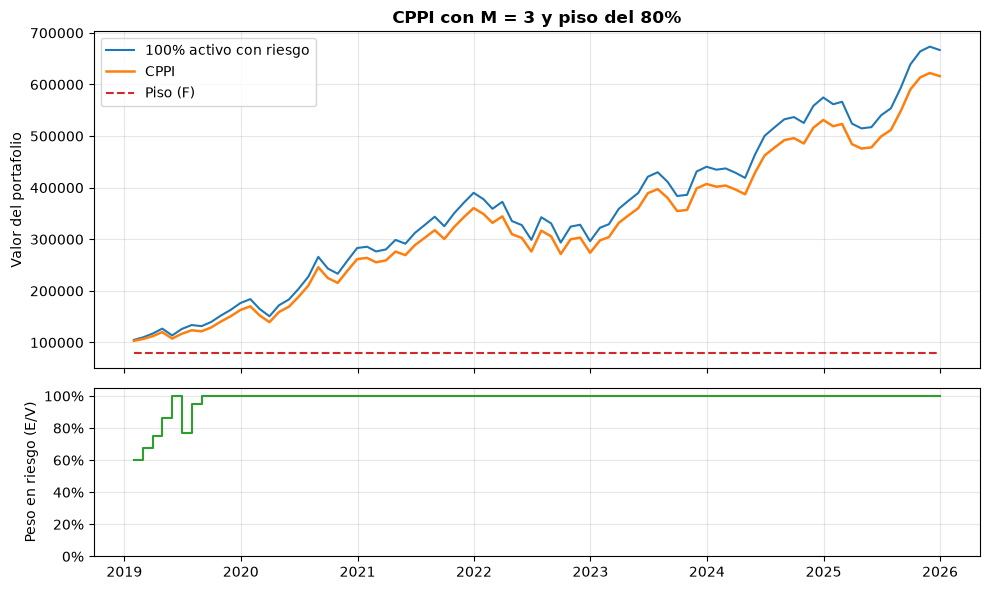

In [13]:
fig, axes = ap.plot_cppi(resultado, titulo=f"CPPI con M = {m} y piso del {piso:.0%}")

**OBSERVACIÓN:** Cuando el MSR sube, el colchón crece y el peso en el activo con riesgo aumenta (hasta 100%). Cuando cae, el colchón se reduce y la estrategia se mueve hacia el activo libre de riesgo.

In [14]:
ap.resumen_cppi(resultado).round(4)

,Valor final,Valor mínimo,Rompió el piso
CPPI,616200.8234,103282.6532,0.0
100% riesgo,666775.1718,105094.1456,0.0


Comparemos también el riesgo con las funciones de los Labs 1 y 2, usando los rendimientos mensuales de cada estrategia (por eso $p = 12$).

In [15]:
rend_estrategias = pd.DataFrame({
    "CPPI": resultado["Rendimiento CPPI"]["MSR"],
    "100% MSR": rend_msr,
})

pd.DataFrame({
    "Rendimiento": ap.rendimiento_anualizado(rend_estrategias, p=12),
    "Volatilidad": ap.volatilidad_anualizada(rend_estrategias, p=12),
    "Sharpe": ap.sharpe_ratio(rend_estrategias, rf, p=12),
    "Max Drawdown": [ap.max_drawdown(rend_estrategias[c])[0] for c in rend_estrategias],
}).round(4)

,Rendimiento,Volatilidad,Sharpe,Max Drawdown
CPPI,0.2966,0.2221,1.0205,-0.247
100% MSR,0.3113,0.2243,1.0757,-0.247


### Efecto del multiplicador M
A mayor M invertimos más en el activo con riesgo: ganamos más cuando el mercado sube, pero el colchón se consume más rápido cuando baja.

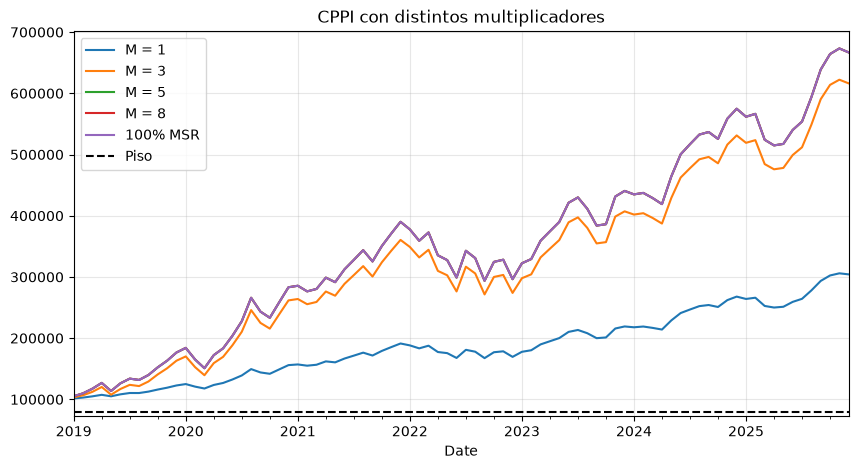

In [16]:
valores_m = [1, 3, 5, 8]
comparacion_m = {}
for valor_m in valores_m:
    res_m = ap.cppi(rend_msr, tasa_libre_de_riesgo=rf, m=valor_m, piso=piso, valor_inicial=valor_inicial)
    comparacion_m[f"M = {valor_m}"] = res_m["Valor CPPI"]["MSR"]

comparacion_m = pd.DataFrame(comparacion_m)
comparacion_m["100% MSR"] = resultado["Valor riesgo"]["MSR"]

ax = comparacion_m.plot(figsize=(10, 5), title="CPPI con distintos multiplicadores")
ax.axhline(piso * valor_inicial, color="black", linestyle="--", label="Piso")
ax.legend()
ax.grid(True, alpha=0.3)

In [17]:
comparacion_m.iloc[-1].round(2)

M = 1       304164.91
M = 3       616200.82
M = 5       666775.17
M = 8       666775.17
100% MSR    666775.17
Name: 2025-12-31 00:00:00, dtype: float64

### Extensión: Max Drawdown
El piso se vuelve dinámico: $F_t = \alpha P_t$, donde $P_t$ es el valor máximo que ha alcanzado el portafolio hasta el tiempo $t$ y $1 - \alpha$ es el máximo drawdown aceptable.

Con un máximo drawdown del 10% ($\alpha = 0.9$), el inversionista busca que se cumpla $V_t > 0.9 P_t$.

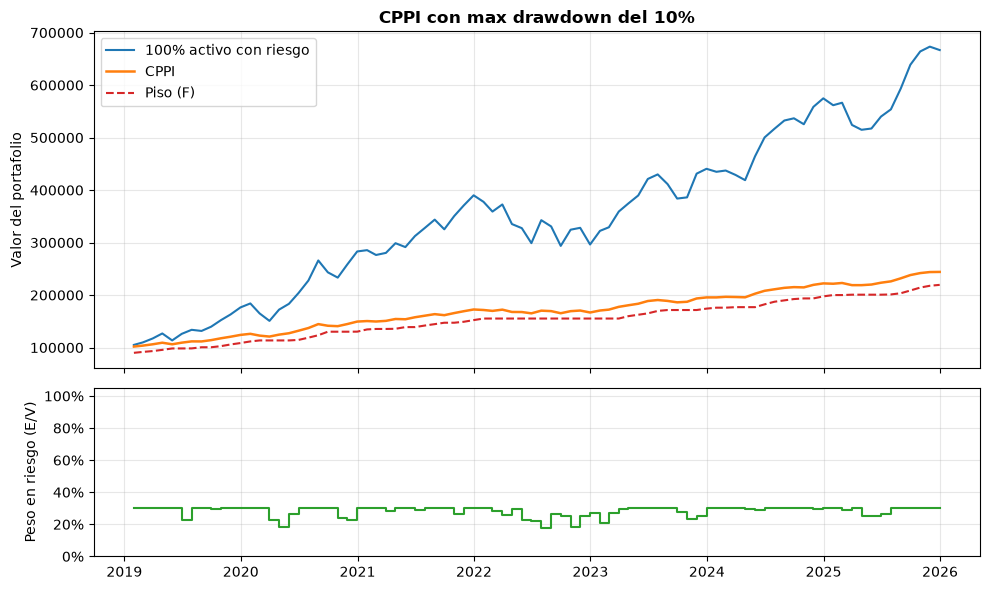

In [18]:
resultado_dd = ap.cppi(rend_msr, tasa_libre_de_riesgo=rf, m=m, valor_inicial=valor_inicial, max_drawdown=0.10)
fig, axes = ap.plot_cppi(resultado_dd, titulo="CPPI con max drawdown del 10%")

In [19]:
rend_dd = resultado_dd["Rendimiento CPPI"]["MSR"]
print(f"Max drawdown CPPI con piso dinámico: {ap.max_drawdown(rend_dd)[0]:.2%}")
print(f"Max drawdown 100% MSR: {ap.max_drawdown(rend_msr)[0]:.2%}")

Max drawdown CPPI con piso dinámico: -4.27%
Max drawdown 100% MSR: -24.70%


**NOTA:** El drawdown puede superar ligeramente el 10% porque sólo rebalanceamos una vez al mes: si el MSR cae mucho dentro del mes, no alcanzamos a ajustar el portafolio. Es el **gap risk** que vimos en la clase 6.

## Simulación de Monte Carlo

Hasta ahora probamos el CPPI con una sola historia: la que ocurrió entre 2019 y 2025. Con la simulación generamos **muchos escenarios posibles** para ver cómo se comportaría la estrategia.

### Movimiento Browniano Geométrico (GBM)

$$ \frac{dS_t}{S_t} = \mu\, dt + \sigma\, dW_t \qquad dW_t \sim N(0, dt) $$

Para simularlo usamos el **esquema de Euler**: escribimos $dW_t = \sqrt{dt}\, Z$ con $Z \sim N(0,1)$, de modo que el rendimiento de cada período es

$$ r_t = \mu\, dt + \sigma \sqrt{dt}\, Z \qquad S_{t+dt} = S_t\,(1 + r_t) $$

Con parámetros anuales y pasos mensuales, $dt = 1/12$.

**¡CUIDADO!** `np.random.normal(0, dt)` recibe la **desviación estándar**, no la varianza. Por eso multiplicamos por $\sqrt{dt}$ y no por $dt$.

### Estimación de los parámetros
* $\sigma$: la volatilidad anualizada de siempre.
* $\mu$: el rendimiento **aritmético** anualizado (media × 252). No usamos `rendimiento_anualizado` del Lab 1 porque ese es geométrico (CAGR) y es menor por aproximadamente $\sigma^2/2$.

In [20]:
mu = ap.rendimiento_aritmetico_anualizado(rend_msr_diario)
sigma = ap.volatilidad_anualizada(rend_msr_diario)
cagr = ap.rendimiento_anualizado(rend_msr_diario)

print(f"mu (aritmético): {mu:.2%}")
print(f"CAGR (geométrico): {cagr:.2%}")
print(f"mu - sigma^2/2: {mu - sigma**2 / 2:.2%}")
print(f"sigma: {sigma:.2%}")

mu (aritmético): 30.82%
CAGR (geométrico): 31.25%
mu - sigma^2/2: 27.21%
sigma: 26.89%


### Simulamos el MSR
1,000 escenarios mensuales a 3 años, empezando en 100.

In [21]:
n_escenarios = 1000
anios = 3

precios_sim = ap.simular_gbm(mu, sigma, n_escenarios=n_escenarios, anios=anios, p=12,
                             valor_inicial=100, semilla=42, precios=True)
precios_sim.iloc[:5, :5].round(2)

,0,1,2,3,4
Período,,,,,
0,100.00,100.00,100.00,100.00,100.00
1,104.93,94.50,108.39,109.87,87.42
2,107.15,91.57,107.69,118.10,89.69
3,106.14,89.19,114.08,123.44,82.21
4,119.16,96.24,134.43,111.78,82.63


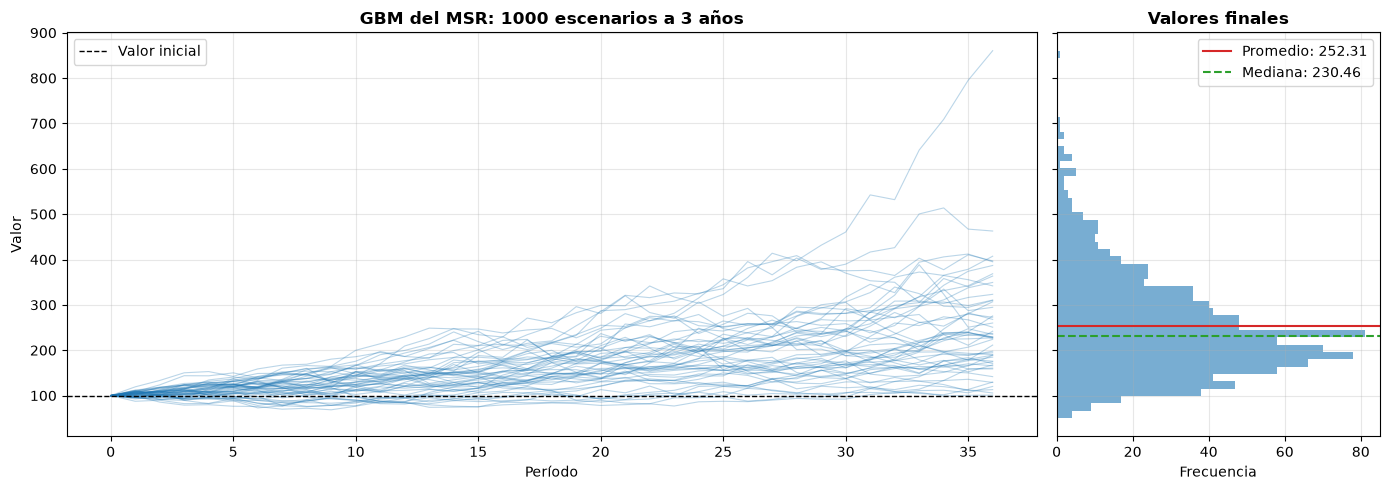

In [22]:
fig, axes = ap.plot_simulacion(precios_sim, titulo=f"GBM del MSR: {n_escenarios} escenarios a {anios} años")

**OBSERVACIÓN:** El promedio de los valores finales es mayor que la mediana. La distribución de los precios es asimétrica a la derecha: unos pocos escenarios muy buenos jalan el promedio hacia arriba, mientras que el escenario "típico" (la mediana) crece más despacio.

In [23]:
finales = precios_sim.iloc[-1]
pd.Series({
    "Promedio simulado": finales.mean(),
    "Promedio teórico 100(1 + mu/12)^36": 100 * (1 + mu / 12) ** (12 * anios),
    "Mediana": finales.median(),
    "Percentil 5": finales.quantile(0.05),
    "Percentil 95": finales.quantile(0.95),
    "Prob. de perder": (finales < 100).mean(),
}).round(4)

Promedio simulado                     252.3136
Promedio teórico 100(1 + mu/12)^36    249.1801
Mediana                               230.4617
Percentil 5                           108.3979
Percentil 95                          469.2940
Prob. de perder                         0.0320
dtype: float64

## CPPI sobre los escenarios simulados
Aplicamos el CPPI a cada escenario usando los **rendimientos** simulados (`precios=False`). Con la misma semilla obtenemos exactamente los mismos escenarios.

In [24]:
rend_sim = ap.simular_gbm(mu, sigma, n_escenarios=n_escenarios, anios=anios, p=12, semilla=42)
resultado_sim = ap.cppi(rend_sim, tasa_libre_de_riesgo=rf, m=m, piso=piso, valor_inicial=valor_inicial)
ap.resumen_cppi(resultado_sim).round(4)

,Valor final promedio,Valor final mediana,Percentil 5,Peor caso,Prob. romper el piso
CPPI,232519.9867,212139.6236,102703.8544,86655.4644,0.000
100% riesgo,252313.6472,230461.6898,108397.8688,50240.0696,0.134


El CPPI sacrifica parte del rendimiento promedio a cambio de proteger los peores escenarios (percentil 5 y peor caso).

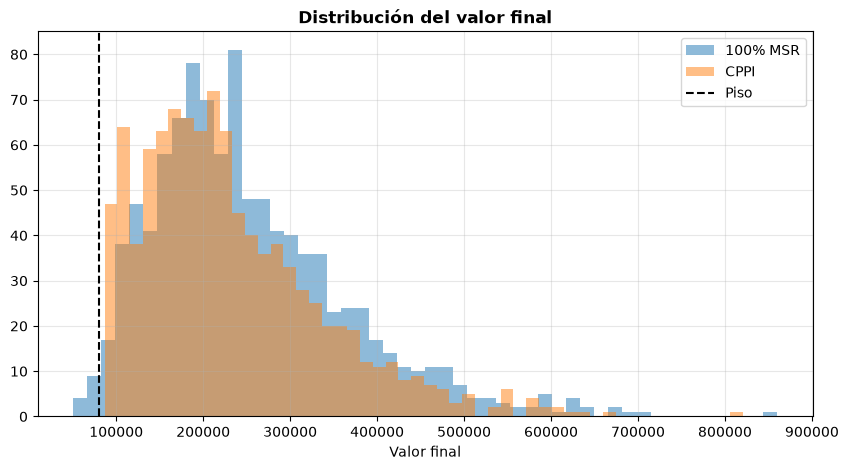

In [25]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(resultado_sim["Valor riesgo"].iloc[-1], bins=50, alpha=0.5, label="100% MSR")
ax.hist(resultado_sim["Valor CPPI"].iloc[-1], bins=50, alpha=0.5, label="CPPI")
ax.axvline(piso * valor_inicial, color="black", linestyle="--", label="Piso")
ax.set_title("Distribución del valor final", fontsize=12, fontweight="bold")
ax.set_xlabel("Valor final")
ax.legend()
ax.grid(True, alpha=0.3)

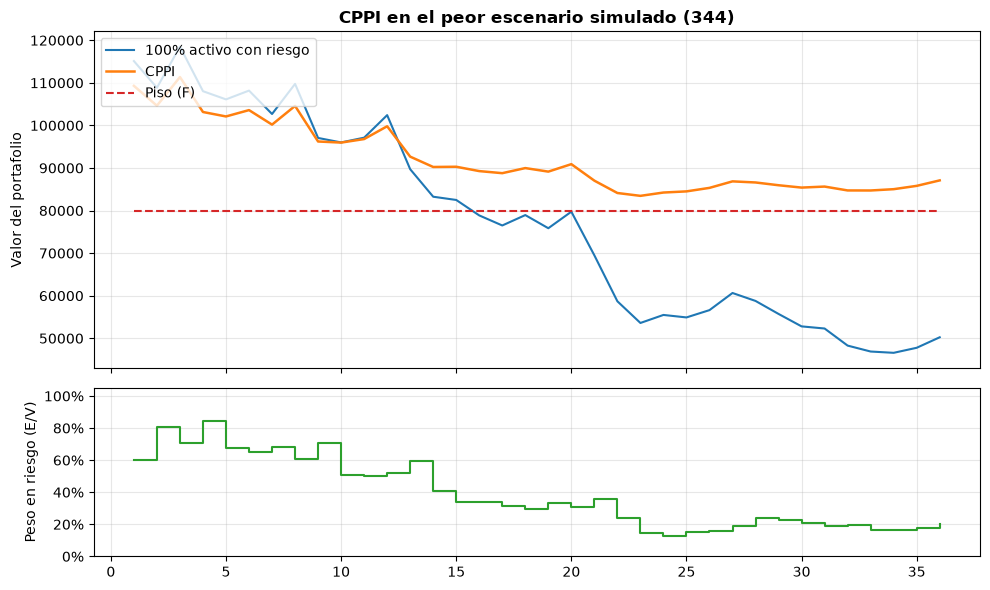

In [26]:
# podemos ver cualquier escenario, por ejemplo el peor para el 100% MSR
peor = resultado_sim["Valor riesgo"].iloc[-1].idxmin()
fig, axes = ap.plot_cppi(resultado_sim, escenario=peor, titulo=f"CPPI en el peor escenario simulado ({peor})")

### Gap risk y el multiplicador M
El piso se rompe si el activo con riesgo cae más de $1/M$ en un solo mes (antes de poder rebalancear). Con $M = 3$ se necesita una caída mayor al 33%; con $M = 8$ basta una caída del 12.5%.

Repetimos la simulación con distintos multiplicadores y medimos la proporción de escenarios en los que el portafolio terminó algún mes por debajo del piso.

In [27]:
gap_risk = {}
for valor_m in [1, 3, 5, 8, 12]:
    res_m = ap.cppi(rend_sim, tasa_libre_de_riesgo=rf, m=valor_m, piso=piso, valor_inicial=valor_inicial)
    gap_risk[f"M = {valor_m}"] = ap.resumen_cppi(res_m).loc["CPPI"]

pd.DataFrame(gap_risk).T.round(4)

,Valor final promedio,Valor final mediana,Percentil 5,Peor caso,Prob. romper el piso
M = 1,157125.4039,151835.1512,118356.3984,101663.3026,0.000
M = 3,232519.9867,212139.6236,102703.8544,86655.4644,0.000
M = 5,243664.6921,221746.0990,95723.1235,82126.5077,0.012
M = 8,245371.3339,225665.0254,92337.5187,78293.4543,0.073
M = 12,245623.3062,226087.2385,88915.8417,74639.8654,0.119


**OBSERVACIÓN:** A mayor M, mayor valor final promedio, pero también mayor probabilidad de romper el piso. Como vimos en la clase 6, para reducir el gap risk podemos usar un M más bajo o rebalancear con mayor frecuencia.

**NOTA:** El GBM supone rendimientos normales, y en la realidad las caídas extremas son más frecuentes (recordemos la curtosis del Lab 2). Por eso el gap risk real suele ser mayor al simulado.

## Resumen de resultados

In [28]:
resumen = pd.Series({
    "Tasa libre de riesgo": rf,
    "Multiplicador M": m,
    "Piso": piso * valor_inicial,
    "Valor final CPPI (histórico)": resultado["Valor CPPI"]["MSR"].iloc[-1],
    "Valor final 100% MSR (histórico)": resultado["Valor riesgo"]["MSR"].iloc[-1],
    "mu (aritmético)": mu,
    "sigma": sigma,
    "Valor final promedio CPPI (simulado)": resultado_sim["Valor CPPI"].iloc[-1].mean(),
    "Valor final promedio 100% MSR (simulado)": resultado_sim["Valor riesgo"].iloc[-1].mean(),
    "Prob. romper el piso CPPI (simulado)": ap.resumen_cppi(resultado_sim).loc["CPPI", "Prob. romper el piso"],
})
resumen.round(4)

Tasa libre de riesgo                             0.0700
Multiplicador M                                  3.0000
Piso                                         80000.0000
Valor final CPPI (histórico)                616200.8234
Valor final 100% MSR (histórico)            666775.1718
mu (aritmético)                                  0.3082
sigma                                            0.2689
Valor final promedio CPPI (simulado)        232519.9867
Valor final promedio 100% MSR (simulado)    252313.6472
Prob. romper el piso CPPI (simulado)             0.0000
dtype: float64